# Bike Rental Demand Prediction Using Machine Learning

## 1. Introduction

Bike-sharing services allow people to rent bicycles for transportation.
The number of bikes rented can change depending on weather conditions,
season, temperature, humidity, and working days.

## 2. Project Objective

1. Perform Exploratory Data Analysis (EDA).
2. Understand the factors affecting bike rental demand.
3. Predict daily bike rental counts using Machine Learning.
4. Compare multiple models using evaluation metrics.
5. Recommend the best-performing model for production.
6. Document the challenges faced and solutions used.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
day_df = pd.read_csv("day.csv")

print("Dataset loaded successfully!")
day_df.head()

Dataset loaded successfully!


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
#Data inspection and understanding
# check the number of rows abd columns
print("no of rows and columns:",day_df.shape)

no of rows and columns: (731, 16)


In [4]:
#check column names
print(day_df.columns.tolist())

['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [5]:
#check datatype of each column
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [6]:
#check missing values
print("missing values in each columns:")
print(day_df.isnull().sum())

missing values in each columns:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [7]:
#check duplicate values-means repeated vales
print("no of duplicate rows:",day_df.duplicated().sum())

no of duplicate rows: 0


In [8]:
#to know statistical summary
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [9]:
#understanding the target variable
print("avg daily rentals:",day_df["cnt"].mean())
print("minimum daily rentals:",day_df["cnt"].min())
print("maximum daily rentals:",day_df["cnt"].max())

avg daily rentals: 4504.3488372093025
minimum daily rentals: 22
maximum daily rentals: 8714


In [10]:
#since dtedat column is object datatype convert it into datetime format which will be easy for data analysis
#data preprocessing
day_df["dteday"]=pd.to_datetime(day_df["dteday"])
print(day_df["dteday"].dtype)
day_df[["dteday"]].head()

datetime64[ns]


,dteday
0,2011-01-01
1,2011-01-02
2,2011-01-03
3,2011-01-04
4,2011-01-05


### task 1
##  Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the
distribution of bike rental demand and identify patterns in the data.
We examine rental counts and their relationship with seasonal,
weather-related, and calendar variables.

### Distribution of Daily Bike Rentals

This analysis examines the distribution of total daily bike rentals
(`cnt`) to understand typical demand, variability, and potential
outliers.

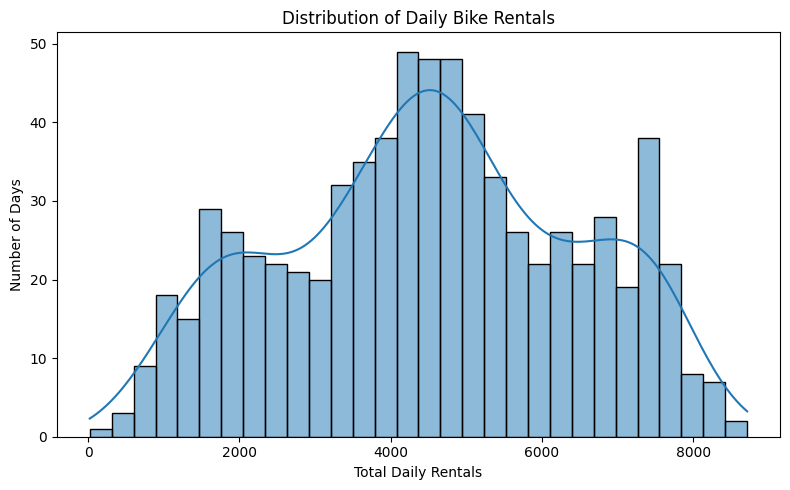

In [11]:
#create distribution chart
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))

sns.histplot(data=day_df, x="cnt", bins=30, kde=True)

plt.title("Distribution of Daily Bike Rentals")
plt.xlabel("Total Daily Rentals")
plt.ylabel("Number of Days")

plt.tight_layout()
plt.show()

### Interpretation of Daily Bike Rental Distribution

The histogram shows the distribution of total daily bike rentals.
Rental demand varies considerably across the observed days, with
many days recording approximately 4,000 to 5,000 rentals.

The distribution is not perfectly symmetric and shows variation
across lower and higher rental counts. This suggests that bike
rental demand changes over time and may be influenced by seasonal,
weather-related, and calendar factors.

Further analysis is required to understand these relationships.

In [12]:
#calculate the statistics
print("Mean:", round(day_df["cnt"].mean(), 2))
print("Median:", round(day_df["cnt"].median(), 2))
print("Standard deviation:", round(day_df["cnt"].std(), 2))
print("Minimum:", day_df["cnt"].min())
print("Maximum:", day_df["cnt"].max())

Mean: 4504.35
Median: 4548.0
Standard deviation: 1937.21
Minimum: 22
Maximum: 8714


### 4.2 Seasonal Bike Rental Analysis

This analysis examines the average daily bike rental count across
the four seasons. The purpose is to identify seasonal variations
in demand and understand how rental activity differs throughout
the year.

In [13]:
season_labels = {
    1: "Winter",
    2: "Spring",
    3: "Summer",
    4: "Fall"
}

season_avg = day_df.groupby("season")["cnt"].mean()

season_avg.index = season_avg.index.map(season_labels)

display(season_avg.round(2))

season
Winter    2604.13
Spring    4992.33
Summer    5644.30
Fall      4728.16
Name: cnt, dtype: float64

### Interpretation of Seasonal Bike Rental Demand

The seasonal analysis shows clear variations in daily bike rental demand.

- **Summer** has the highest average demand, with approximately 5,644 rentals per day.
- **Spring** records an average of approximately 4,992 rentals per day.
- **Fall** records an average of approximately 4,728 rentals per day.
- **Winter** has the lowest average demand, with approximately 2,604 rentals per day.

These results indicate that bike rental demand varies across seasons. The higher average demand in summer and lower average demand in winter may be associated with seasonal conditions. Further analysis of weather and temperature variables can help investigate these patterns.

**Business implication:** Bike rental operators could consider seasonal demand when planning bicycle availability and maintenance.


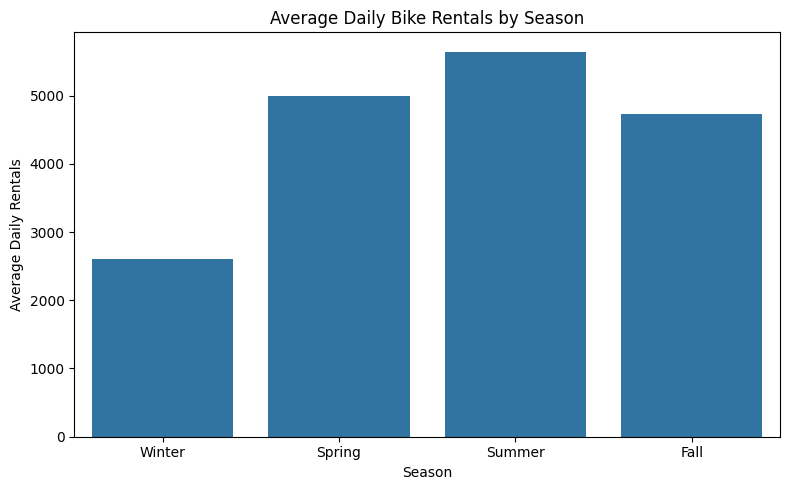

In [14]:
#create seasonal bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=season_avg.index,
    y=season_avg.values,
    errorbar=None
)

plt.title("Average Daily Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Daily Rentals")

plt.tight_layout()
plt.show()

In [15]:
# Average daily rentals by month

monthly_avg = day_df.groupby("mnth")["cnt"].mean()

display(monthly_avg.round(2))

mnth
1     2176.34
2     2655.30
3     3692.26
4     4484.90
5     5349.77
6     5772.37
7     5563.68
8     5664.42
9     5766.52
10    5199.23
11    4247.18
12    3403.81
Name: cnt, dtype: float64

### Interpretation of Monthly Bike Rental Demand

The monthly analysis shows that average daily bike rentals vary throughout the year.

- June records the highest average daily demand, at approximately 5,772 rentals.
- January records the lowest average daily demand, at approximately 2,176 rentals.
- Average demand increases during the first half of the year, remains relatively high during the middle months, and decreases toward the end of the year.

These findings suggest that bike rental demand follows a seasonal pattern. This information may help operators plan bicycle availability according to expected demand.

Further analysis of weather conditions and temperature can help investigate factors associated with these variations.


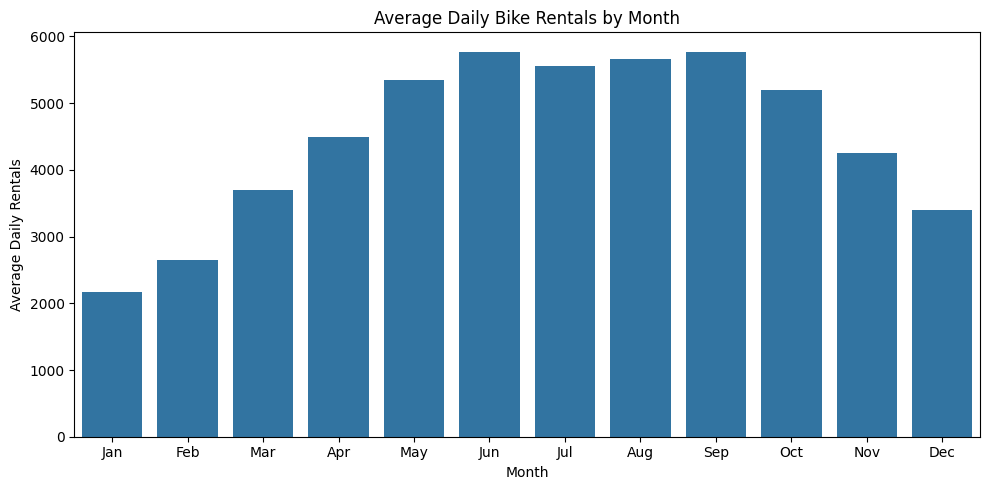

In [16]:
# Average daily rentals by month

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_avg.index,
    y=monthly_avg.values,
    errorbar=None
)

plt.title("Average Daily Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Rentals")
plt.xticks(range(12), month_names)

plt.tight_layout()
plt.show()

### 4.4 Bike Rental Demand by Weather Condition

This analysis examines the relationship between weather conditions
and average daily bike rental counts. The purpose is to understand
how rental demand varies across different weather situations.

In [17]:
# Average daily rentals by weather condition

weather_avg = day_df.groupby("weathersit")["cnt"].mean()

display(weather_avg.round(2))

weathersit
1    4876.79
2    4035.86
3    1803.29
Name: cnt, dtype: float64

### Interpretation of Weather Conditions

The analysis indicates that weather conditions are associated with differences in average daily bike rental demand.

- **Weather condition 1:** Recorded the highest average demand, with approximately 4,877 rentals per day.
- **Weather condition 2:** Recorded approximately 4,036 rentals per day.
- **Weather condition 3:** Recorded the lowest average demand, with approximately 1,803 rentals per day.

The results suggest that bike rental demand tends to be higher in clearer weather and lower under adverse weather conditions. This relationship may be useful when planning bicycle availability and operations.

Note: These are observed averages and do not establish that weather alone causes changes in demand.


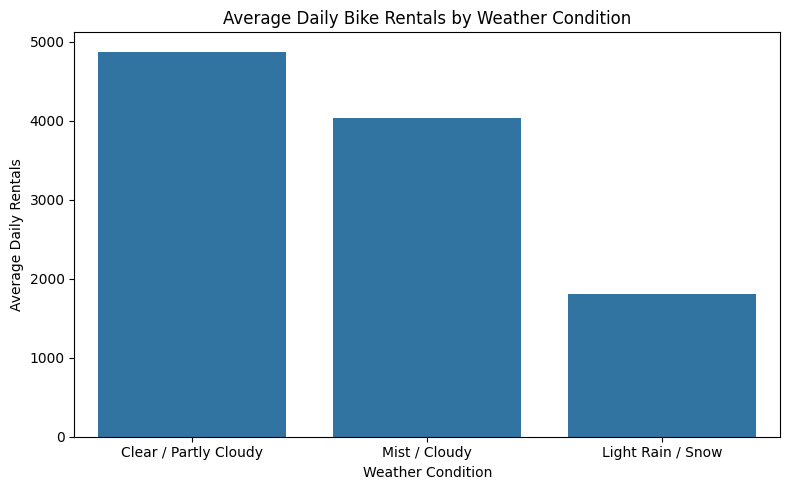

In [18]:
# Average daily rentals by weather condition

plt.figure(figsize=(8, 5))

sns.barplot(
    x=weather_avg.index,
    y=weather_avg.values,
    errorbar=None
)

plt.title("Average Daily Bike Rentals by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Daily Rentals")
plt.xticks([0, 1, 2], [
    "Clear / Partly Cloudy",
    "Mist / Cloudy",
    "Light Rain / Snow"
])

plt.tight_layout()
plt.show()

### 4.5 Temperature and Bike Rental Demand

This analysis investigates the relationship between normalized
temperature and daily bike rental counts. It helps us understand
whether rental demand tends to vary with temperature.

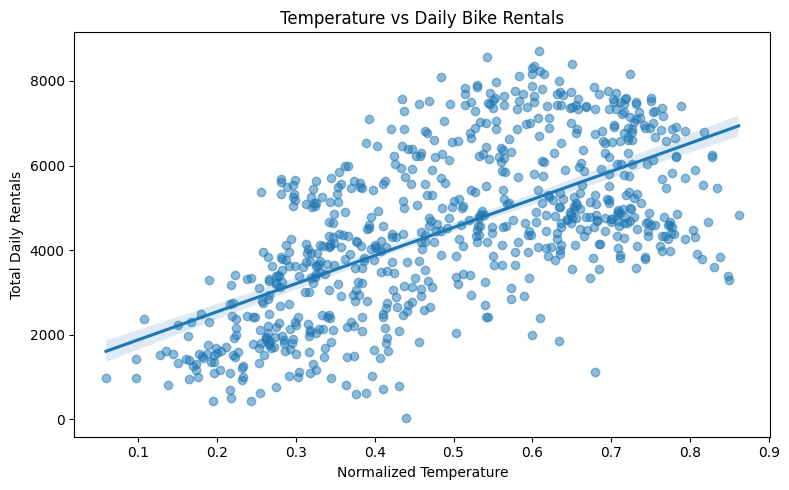

In [19]:
# Relationship between temperature and daily rentals

plt.figure(figsize=(8, 5))

sns.regplot(
    data=day_df,
    x="temp",
    y="cnt",
    scatter_kws={"alpha": 0.5}
)

plt.title("Temperature vs Daily Bike Rentals")
plt.xlabel("Normalized Temperature")
plt.ylabel("Total Daily Rentals")

plt.tight_layout()
plt.show()

### Interpretation of Temperature vs Daily Bike Rentals

The scatter plot illustrates the relationship between normalized temperature and total daily bike rentals. The upward-sloping regression line indicates a positive relationship between temperature and rental demand.

The graph suggests that days with higher temperatures tend to have higher rental counts. However, the considerable spread of data points around the regression line indicates that temperature alone cannot fully explain variations in bike rental demand.

Other factors, such as season, weather conditions, and calendar variables, may also influence rental patterns. These variables will be explored further during the analysis.

**Conclusion:** Temperature appears to be a useful feature for understanding and predicting daily bike rental demand.


### 4.6 Humidity and Bike Rental Demand

This analysis examines the relationship between normalized humidity
and total daily bike rentals to understand how rental demand varies
with humidity levels.

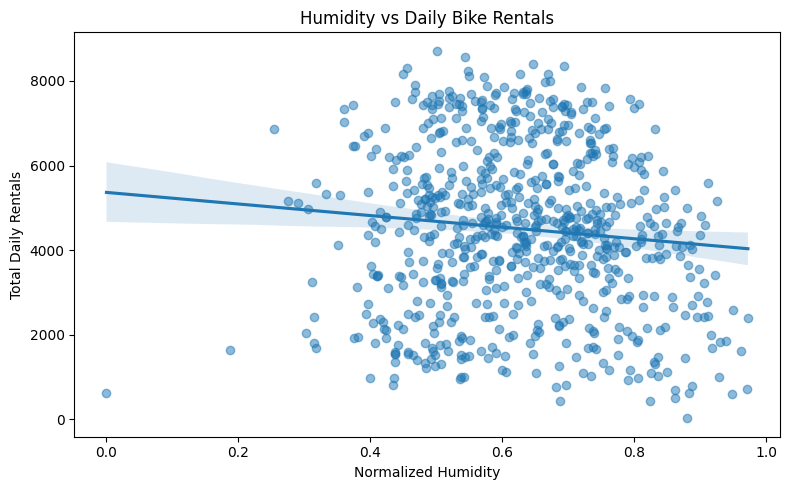

In [20]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=day_df,
    x="hum",
    y="cnt",
    scatter_kws={"alpha": 0.5}
)

plt.title("Humidity vs Daily Bike Rentals")
plt.xlabel("Normalized Humidity")
plt.ylabel("Total Daily Rentals")

plt.tight_layout()
plt.show()

### Interpretation of Humidity vs Daily Bike Rentals

The scatter plot illustrates the relationship between normalized humidity and total daily bike rentals. The downward-sloping regression line suggests a negative relationship between humidity and rental demand.

However, the data points are widely distributed around the regression line, indicating that humidity alone does not explain variations in daily rentals. Other factors, including temperature, season, weather conditions, and calendar variables, may also contribute to differences in demand.

**Conclusion:** Humidity may be a useful feature for understanding bike rental demand, but its predictive importance should be evaluated alongside other variables during model development.


### 4.7 Wind Speed and Bike Rental Demand

This analysis examines the relationship between normalized wind
speed and total daily bike rentals to understand whether rental
demand varies with wind conditions.

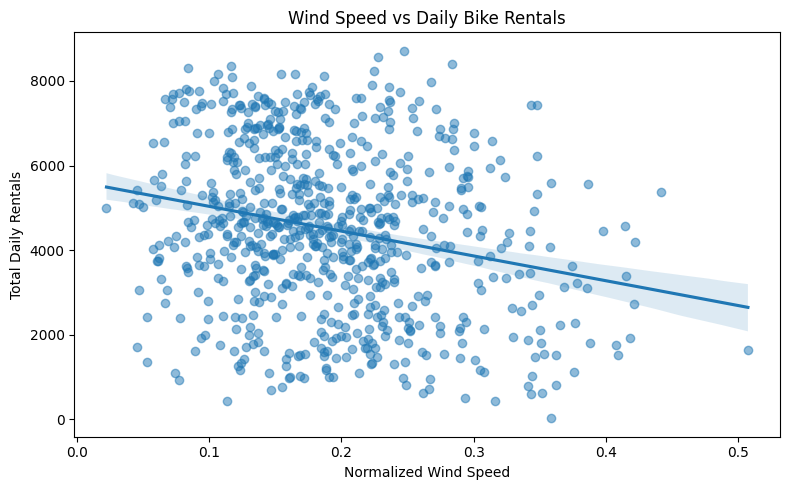

In [21]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=day_df,
    x="windspeed",
    y="cnt",
    scatter_kws={"alpha": 0.5}
)

plt.title("Wind Speed vs Daily Bike Rentals")
plt.xlabel("Normalized Wind Speed")
plt.ylabel("Total Daily Rentals")

plt.tight_layout()
plt.show()

### Interpretation of Wind Speed vs Daily Bike Rentals

The scatter plot illustrates the relationship between normalized wind speed and total daily bike rentals. The downward-sloping regression line suggests a negative relationship between wind speed and rental demand.

The data points show considerable variation around the trend line, indicating that wind speed alone cannot fully explain daily rental demand. Other factors, including temperature, humidity, season, and weather conditions, may also contribute to changes in rental activity.

**Conclusion:** Wind speed may provide useful information for understanding bike rental demand. Its predictive value should be evaluated together with other features during model development.


### 4.8 Working Days and Holiday Analysis

This analysis compares average daily bike rentals across working
days, non-working days, and holidays to understand how calendar
patterns are associated with rental demand.

In [22]:
# Average rentals on working and non-working days

workingday_avg = day_df.groupby("workingday")["cnt"].mean()

print("Average rentals by working-day status:")
display(workingday_avg.round(2))

# Average rentals on holidays and non-holidays

holiday_avg = day_df.groupby("holiday")["cnt"].mean()

print("Average rentals by holiday status:")
display(holiday_avg.round(2))

Average rentals by working-day status:


workingday
0    4330.17
1    4584.82
Name: cnt, dtype: float64

Average rentals by holiday status:


holiday
0    4527.1
1    3735.0
Name: cnt, dtype: float64

### Interpretation of Working Days and Holidays

The analysis compares average daily bike rentals according to working-day and holiday status.

Working days record an average of approximately 4,585 rentals, compared with approximately 4,330 rentals on non-working days. This indicates slightly higher average demand on working days in the dataset.

Non-holidays record an average of approximately 4,527 rentals, while holidays record approximately 3,735 rentals. This suggests lower average rental demand on holidays.

These patterns may help bike-sharing operators plan bicycle availability. Further analysis is needed to understand how these differences relate to season, weather and other factors.


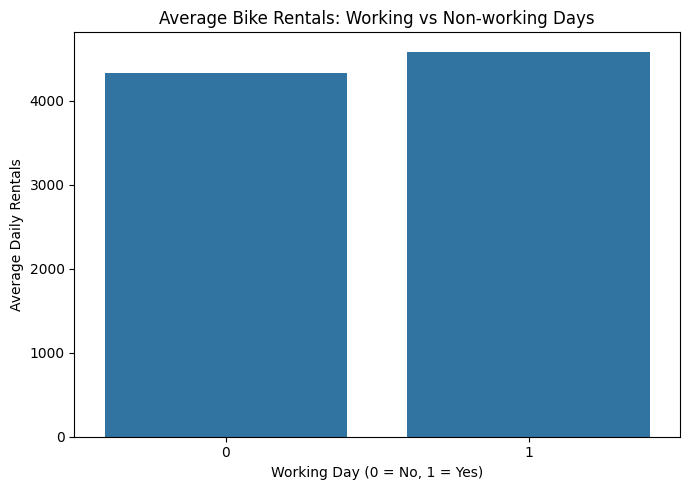

In [23]:
# Compare working days and non-working days

plt.figure(figsize=(7, 5))

sns.barplot(
    x=workingday_avg.index,
    y=workingday_avg.values,
    errorbar=None
)

plt.title("Average Bike Rentals: Working vs Non-working Days")
plt.xlabel("Working Day (0 = No, 1 = Yes)")
plt.ylabel("Average Daily Rentals")

plt.tight_layout()
plt.show()

### 4.9 Correlation Analysis

Correlation analysis is used to examine the strength and direction
of relationships between numerical variables. A correlation heatmap
helps identify variables associated with daily bike rental demand.
Correlation does not necessarily imply causation.

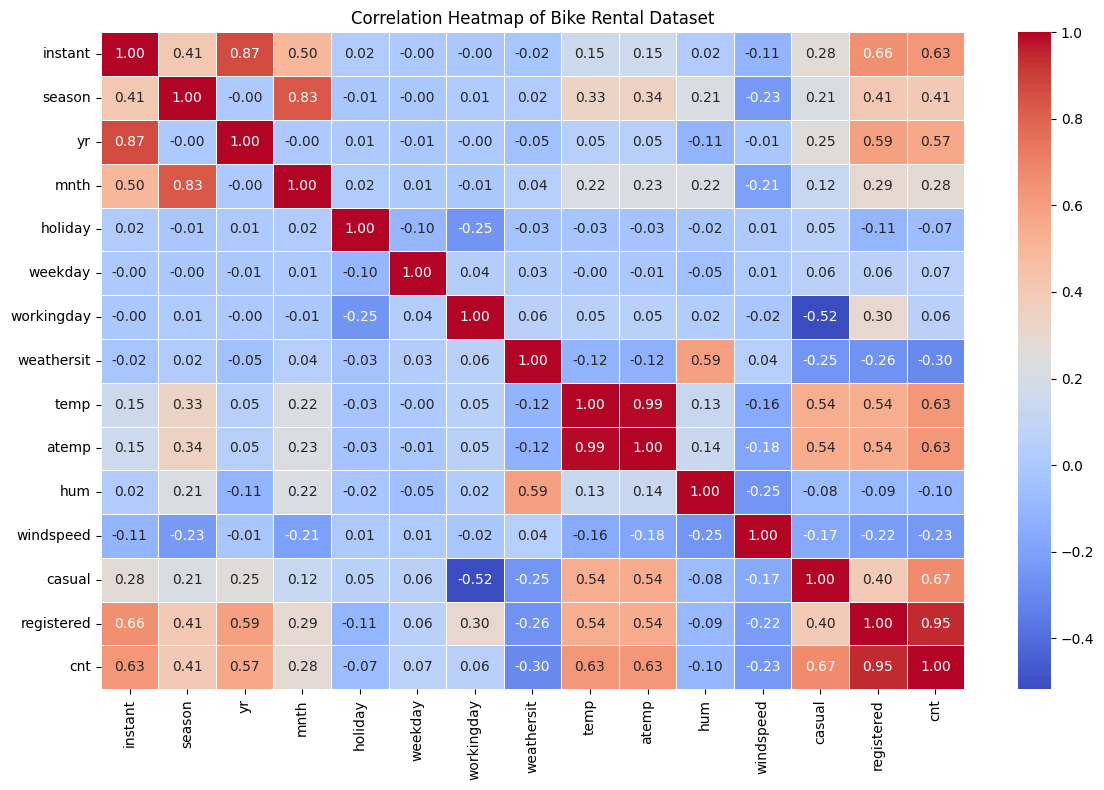

In [24]:
# Correlation between numerical variables

numeric_df = day_df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Bike Rental Dataset")
plt.tight_layout()
plt.show()

### Interpretation of Correlation Analysis

The correlation heatmap shows the relationships between numerical variables in the bike rental dataset.

The total rental count (`cnt`) has a strong positive correlation with temperature (`temp`, 0.63) and apparent temperature (`atemp`, 0.63). The year variable (`yr`, 0.57) and season (`season`, 0.41) also show positive relationships with rental counts.

Weather situation (`weathersit`, -0.30) and wind speed (`windspeed`, -0.23) show negative relationships with rental demand, while humidity (`hum`, -0.10), holiday (`holiday`, -0.07), and working-day status (`workingday`, 0.07) have relatively weak linear relationships.

The high correlations of `casual` (0.67) and `registered` (0.95) with `cnt` are expected because these variables contribute directly to the total rental count. They will therefore be excluded from the model's input features to avoid target leakage.

**Conclusion:** Temperature, season, year, and weather situation are useful variables to investigate further during model development. Correlation values alone do not establish causation or determine the final predictive importance of a feature.


### 4.10 Summary of Exploratory Data Analysis

The exploratory data analysis identified several patterns in daily bike rental demand:

1. **Seasonal demand:** Summer recorded the highest average daily rental count, while winter recorded the lowest.
2. **Monthly demand:** June had the highest average daily rental count, while January had the lowest.
3. **Weather conditions:** Clear or partly cloudy conditions had higher average rentals than the more adverse weather categories observed.
4. **Temperature:** The scatter plot showed a positive relationship between temperature and rental demand.
5. **Humidity:** The regression trend indicated a weak negative relationship with rental demand.
6. **Wind speed:** The regression trend indicated a negative relationship with rental demand.
7. **Calendar patterns:** Average rentals were higher on working days than on non-working days, while holidays had lower average rentals than non-holidays.
8. **Correlation analysis:** Temperature, apparent temperature, year, and season showed positive correlations with total rental count.

These findings provide a foundation for preparing the dataset and developing machine learning models. The relationships identified during EDA will be evaluated further using model performance metrics.


## 5. Data Preparation and Feature Engineering

In this section, the dataset is prepared for machine learning.
The target variable is the total daily rental count (`cnt`).
Appropriate input features are selected, data leakage is avoided,
and the dataset is divided into training and testing sets.

In [25]:
# Create a copy for model development
model_df = day_df.copy()

# Remove columns that directly reveal the target
model_df = model_df.drop(
    columns=["casual", "registered"],
    errors="ignore"
)

# Separate features and target
X = model_df.drop(columns=["cnt", "dteday"], errors="ignore")
y = model_df["cnt"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nInput features:")
print(X.columns.tolist())

Feature shape: (731, 12)
Target shape: (731,)

Input features:
['instant', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (584, 12)
Testing features: (147, 12)
Training target: (584,)
Testing target: (147,)


## 6. Model Building and Evaluation

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(3))

,Model,MAE,RMSE,R2
2,Gradient Boosting,438.860,659.306,0.892
1,Random Forest,440.892,695.706,0.879
0,Linear Regression,613.590,824.230,0.831


### 6.1 Model Performance Comparison

Three regression models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

Gradient Boosting achieved the best initial performance, with an MAE of 438.860, an RMSE of 659.306, and an R² score of 0.892. Random Forest achieved an R² score of 0.879, while Linear Regression achieved 0.831.

Gradient Boosting produced the lowest MAE and RMSE and the highest R² among the three evaluated models. Therefore, it is selected as the leading candidate for further hyperparameter tuning and validation.

The final production recommendation will be made after evaluating the tuned model and reviewing its prediction errors.


### 6.2 Hyperparameter Tuning

Hyperparameter tuning is performed to identify suitable settings
for the Gradient Boosting Regressor. Grid Search with cross-validation
is used to compare different parameter combinations using RMSE.

In [28]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

# Define parameter combinations to test
param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3]
}

# Create the base model
gb_model = GradientBoostingRegressor(random_state=42)

# Search for the best settings using cross-validation
grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation RMSE:")
print(round(-grid_search.best_score_, 3))

Best parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}

Best cross-validation RMSE:
644.108


In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_model = grid_search.best_estimator_

tuned_predictions = best_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)

print("Tuned Gradient Boosting Results")
print("MAE:", round(tuned_mae, 3))
print("RMSE:", round(tuned_rmse, 3))
print("R2:", round(tuned_r2, 3))

Tuned Gradient Boosting Results
MAE: 426.334
RMSE: 644.803
R2: 0.896


In [30]:
comparison = pd.DataFrame([
    {
        "Model": "Original Gradient Boosting",
        "MAE": 438.860,
        "RMSE": 659.306,
        "R2": 0.892
    },
    {
        "Model": "Tuned Gradient Boosting",
        "MAE": tuned_mae,
        "RMSE": tuned_rmse,
        "R2": tuned_r2
    }
])

display(comparison.round(3))

,Model,MAE,RMSE,R2
0,Original Gradient Boosting,438.860,659.306,0.892
1,Tuned Gradient Boosting,426.334,644.803,0.896


## 7. Model Comparison Report

Three regression models were initially evaluated: Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor.

Gradient Boosting achieved the best initial performance, with an MAE of 438.860, an RMSE of 659.306, and an R² score of 0.892.

Hyperparameter tuning was then performed using Grid Search with five-fold cross-validation. The tuned Gradient Boosting model achieved an MAE of 426.334, an RMSE of 644.803, and an R² score of 0.896 on the held-out test set.

Compared with the original Gradient Boosting model, the tuned model reduced MAE and RMSE and improved R². Therefore, the tuned Gradient Boosting model is selected as the current best candidate for daily bike rental prediction.

This recommendation is based on the present evaluation. Further validation on chronological or future-day data is recommended before production deployment.


In [31]:
# Compare actual and predicted rental counts

prediction_results = pd.DataFrame({
    "Actual Rentals": y_test.values,
    "Predicted Rentals": tuned_predictions
})

prediction_results["Error"] = (
    prediction_results["Actual Rentals"]
    - prediction_results["Predicted Rentals"]
)

display(prediction_results.head(10).round(2))

,Actual Rentals,Predicted Rentals,Error
0,6606,6638.46,-32.46
1,1550,1535.50,14.50
2,3747,3523.05,223.95
3,6041,5612.17,428.83
4,7538,7687.05,-149.05
5,7264,7038.23,225.77
6,1605,1534.26,70.74
7,2209,2942.13,-733.13
8,7499,7028.98,470.02
9,5743,6683.34,-940.34


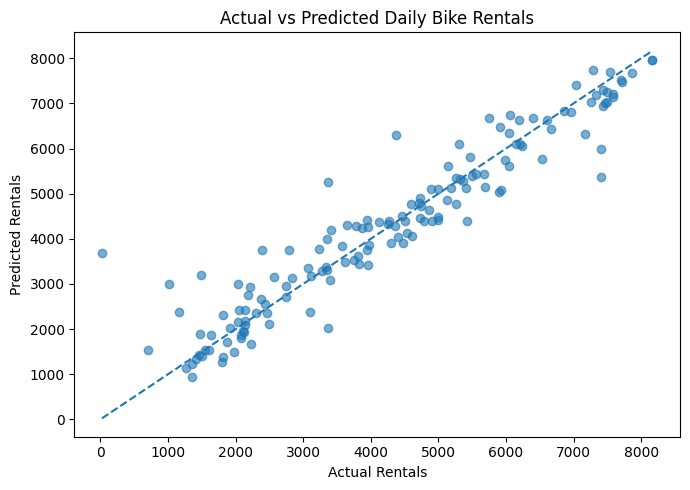

In [32]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, tuned_predictions, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Daily Bike Rentals")
plt.xlabel("Actual Rentals")
plt.ylabel("Predicted Rentals")

plt.tight_layout()
plt.show()

### 8. Prediction Analysis: Actual vs Predicted Rentals

The actual-versus-predicted scatter plot evaluates how closely the tuned Gradient Boosting model's predictions match the observed daily bike rental counts.

Many points lie near the diagonal reference line, indicating good agreement between actual and predicted values for many observations. However, some points deviate noticeably from the line, indicating prediction errors on certain days.

This visualization complements the quantitative evaluation metrics. The tuned model achieved an MAE of 426.334, an RMSE of 644.803, and an R² score of 0.896 on the held-out test set.

**Conclusion:** The model captures much of the variation in daily rental demand, although some prediction errors remain.


## 9. Challenges Faced Report

### Challenge 1: Understanding the Dataset

**Challenge:** The dataset contains several environmental, seasonal, and calendar variables.

**Technique used:** Exploratory Data Analysis using summary statistics, charts, and a correlation heatmap.

**Reason:** These techniques helped identify patterns in rental demand and understand relationships between variables.

### Challenge 2: Avoiding Target Leakage

**Challenge:** The `casual` and `registered` columns directly contribute to the target variable `cnt`.

**Technique used:** Excluded `casual` and `registered` from the model input features.

**Reason:** This prevents the model from using components of the target to predict the target itself.

### Challenge 3: Selecting a Suitable Prediction Model

**Challenge:** Different regression models can produce different prediction errors.

**Technique used:** Compared Linear Regression, Random Forest, and Gradient Boosting using MAE, RMSE, and R².

**Reason:** Comparing multiple metrics provides a more balanced assessment of predictive performance.

### Challenge 4: Improving Model Performance

**Challenge:** The initial Gradient Boosting model could potentially achieve better results with different parameter settings.

**Technique used:** Grid Search with five-fold cross-validation.

**Reason:** This systematically evaluates parameter combinations and identifies promising settings using validation performance.

### Challenge 5: Prediction Errors

**Challenge:** The actual-versus-predicted plot shows that some predictions deviate from the ideal reference line.

**Technique used:** Compared actual and predicted values and evaluated errors using MAE and RMSE.

**Reason:** These methods help assess prediction accuracy and identify opportunities for future improvement.

### Overall Learning

The project demonstrated the importance of data exploration, careful feature selection, model comparison, hyperparameter tuning, and evaluation using unseen test data.


## 10. Conclusion and Future Scope

### Conclusion

This project focused on analyzing and predicting daily bike rental demand using environmental, seasonal, and calendar-related variables.

Exploratory Data Analysis revealed variations in rental demand across seasons, months, weather conditions, and temperature levels. The analysis also highlighted relationships between numerical variables and daily rental counts.

Three regression models—Linear Regression, Random Forest, and Gradient Boosting—were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

The initial Gradient Boosting model achieved an MAE of 438.860, an RMSE of 659.306, and an R² of 0.892. After hyperparameter tuning, the model achieved an MAE of 426.334, an RMSE of 644.803, and an R² of 0.896 on the held-out test set.

The tuned Gradient Boosting model is therefore the leading candidate among the models evaluated in this experiment. Further validation on chronological or future-day data is recommended before production deployment.

### Future Scope

1. Evaluate the model on a chronological test set to simulate future-day predictions.
2. Investigate additional features that may improve rental demand prediction.
3. Monitor prediction errors and retrain the model when demand patterns change.
4. Develop a dashboard to display predicted demand and support operational planning.
